<a href="https://colab.research.google.com/github/Sai-charan822/DSA03-NLP/blob/main/LAB14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 14. Sentence Agreement Checker using CFG
We will use the Natural Language Toolkit (`nltk`) to define a Context-Free Grammar that enforces agreement rules (e.g., singular subject with singular verb, plural subject with plural verb) and test it on various sentences.

Sentence: "the cat chases the dogs"
Result: Valid sentence (Grammatically Correct with Agreement)
Parse Tree:


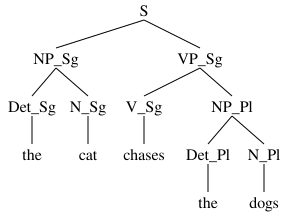

--------------------------------------------------
Sentence: "the cats chase the dog"
Result: Valid sentence (Grammatically Correct with Agreement)
Parse Tree:


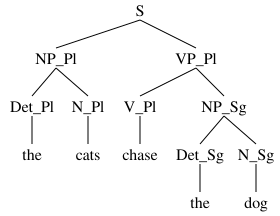

--------------------------------------------------
Sentence: "the cat chase the dogs"
Result: Invalid sentence (Agreement or Grammar Violation)
--------------------------------------------------
Sentence: "the cats chases the dog"
Result: Invalid sentence (Agreement or Grammar Violation)
--------------------------------------------------
Sentence: "John likes apples"
Result: Valid sentence (Grammatically Correct with Agreement)
Parse Tree:


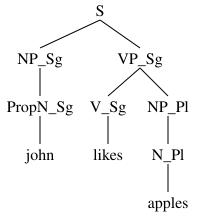

--------------------------------------------------
Sentence: "many dogs eat apples"
Result: Valid sentence (Grammatically Correct with Agreement)
Parse Tree:


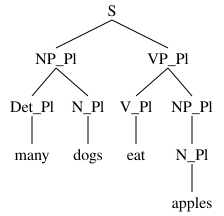

--------------------------------------------------


In [3]:
!pip install svgling -q
import nltk

# Define a CFG with agreement rules (using lowercase terminals for consistency)
agreement_grammar = nltk.CFG.fromstring("""
    S -> NP_Sg VP_Sg | NP_Pl VP_Pl

    NP_Sg -> Det_Sg N_Sg | PropN_Sg
    NP_Pl -> Det_Pl N_Pl | N_Pl

    VP_Sg -> V_Sg | V_Sg NP_Sg | V_Sg NP_Pl
    VP_Pl -> V_Pl | V_Pl NP_Sg | V_Pl NP_Pl

    Det_Sg -> 'the' | 'a' | 'this'
    Det_Pl -> 'the' | 'these' | 'many'

    PropN_Sg -> 'john' | 'mary'

    N_Sg -> 'cat' | 'dog' | 'apple'
    N_Pl -> 'cats' | 'dogs' | 'apples'

    V_Sg -> 'chases' | 'eats' | 'likes'
    V_Pl -> 'chase' | 'eat' | 'like'
""")

# Initialize the Chart Parser with our grammar
parser = nltk.ChartParser(agreement_grammar)

def check_agreement(sentence):
    words = sentence.lower().split()
    print(f"Sentence: \"{sentence}\"")
    try:
        trees = list(parser.parse(words))
        if trees:
            print("Result: Valid sentence (Grammatically Correct with Agreement)")
            for tree in trees:
                print("Parse Tree:")
                display(tree)
        else:
            print("Result: Invalid sentence (Agreement or Grammar Violation)")
    except ValueError as e:
        print(f"Result: Invalid sentence (Contains words outside our vocabulary)")
    print("-" * 50)

# Test cases
test_sentences = [
    "the cat chases the dogs",
    "the cats chase the dog",
    "the cat chase the dogs",  # Agreement error (singular noun, plural verb)
    "the cats chases the dog",  # Agreement error (plural noun, singular verb)
    "John likes apples",
    "many dogs eat apples"
]

for sent in test_sentences:
    check_agreement(sent)